# 1. Dataset Loading and Integration

This section loads and integrates the CICIoMT2024 training datasets into a single DataFrame for subsequent preprocessing and exploratory data analysis.

In [1]:
import pandas as pd
from pathlib import Path

train_path = Path("C:/Users/iskit/Desktop/iomt_proje/data/train")

train_files = sorted(train_path.glob("*.csv"))

print(f"Total training files: {len(train_files)}")

Total training files: 51


# 2. Attack Type Identification and Binary Labeling

Attack types are derived from the source CSV filenames. A binary target variable is then assigned to distinguish benign traffic (0) from malicious traffic (1).

The original attack type labels are retained for detailed class distribution analysis.

## 2.1 Train Dataset Loading and Labeling

In [2]:
df_list = []

for file in train_files:
    df = pd.read_csv(file, low_memory=False)

    attack_type = file.name.removesuffix("_train.pcap.csv")

    df["Attack_Type"] = attack_type
    df["Label"] = 0 if attack_type.lower() == "benign" else 1

    df_list.append(df)

df_train_full = pd.concat(df_list, ignore_index=True)

print(f"Training dataset shape: {df_train_full.shape}")
print(f"Unique attack types: {df_train_full['Attack_Type'].nunique()}")
print(f"Binary labels: {df_train_full['Label'].unique()}")

Training dataset shape: (7160831, 47)
Unique attack types: 51
Binary labels: [1 0]


In [3]:
print(df_train_full["Attack_Type"].unique())

['ARP_Spoofing' 'Benign' 'MQTT-DDoS-Connect_Flood'
 'MQTT-DDoS-Publish_Flood' 'MQTT-DoS-Connect_Flood'
 'MQTT-DoS-Publish_Flood' 'MQTT-Malformed_Data' 'Recon-OS_Scan'
 'Recon-Ping_Sweep' 'Recon-Port_Scan' 'Recon-VulScan' 'TCP_IP-DDoS-ICMP1'
 'TCP_IP-DDoS-ICMP2' 'TCP_IP-DDoS-ICMP3' 'TCP_IP-DDoS-ICMP4'
 'TCP_IP-DDoS-ICMP5' 'TCP_IP-DDoS-ICMP6' 'TCP_IP-DDoS-ICMP7'
 'TCP_IP-DDoS-ICMP8' 'TCP_IP-DDoS-SYN1' 'TCP_IP-DDoS-SYN2'
 'TCP_IP-DDoS-SYN3' 'TCP_IP-DDoS-SYN4' 'TCP_IP-DDoS-TCP1'
 'TCP_IP-DDoS-TCP2' 'TCP_IP-DDoS-TCP3' 'TCP_IP-DDoS-TCP4'
 'TCP_IP-DDoS-UDP1' 'TCP_IP-DDoS-UDP2' 'TCP_IP-DDoS-UDP3'
 'TCP_IP-DDoS-UDP4' 'TCP_IP-DDoS-UDP5' 'TCP_IP-DDoS-UDP6'
 'TCP_IP-DDoS-UDP7' 'TCP_IP-DDoS-UDP8' 'TCP_IP-DoS-ICMP1'
 'TCP_IP-DoS-ICMP2' 'TCP_IP-DoS-ICMP3' 'TCP_IP-DoS-ICMP4'
 'TCP_IP-DoS-SYN1' 'TCP_IP-DoS-SYN2' 'TCP_IP-DoS-SYN3' 'TCP_IP-DoS-SYN4'
 'TCP_IP-DoS-TCP1' 'TCP_IP-DoS-TCP2' 'TCP_IP-DoS-TCP3' 'TCP_IP-DoS-TCP4'
 'TCP_IP-DoS-UDP1' 'TCP_IP-DoS-UDP2' 'TCP_IP-DoS-UDP3' 'TCP_IP-DoS-UDP4']


In [4]:
df_train_full["Source_File"] = df_train_full["Attack_Type"]

df_train_full["Attack_Type"] = (
    df_train_full["Attack_Type"]
    .str.replace(r"(?<=\D)\d+$", "", regex=True)
)

print("Unique source files:", df_train_full["Source_File"].nunique())
print("Unique attack types:", df_train_full["Attack_Type"].nunique())
print(df_train_full["Attack_Type"].value_counts())

Unique source files: 51
Unique attack types: 19
Attack_Type
TCP_IP-DDoS-UDP            1635956
TCP_IP-DDoS-ICMP           1537476
TCP_IP-DDoS-TCP             804465
TCP_IP-DDoS-SYN             801962
TCP_IP-DoS-UDP              566950
TCP_IP-DoS-SYN              441903
TCP_IP-DoS-ICMP             416292
TCP_IP-DoS-TCP              380384
Benign                      192732
MQTT-DDoS-Connect_Flood     173036
Recon-Port_Scan              83981
MQTT-DoS-Publish_Flood       44376
MQTT-DDoS-Publish_Flood      27623
Recon-OS_Scan                16832
ARP_Spoofing                 16047
MQTT-DoS-Connect_Flood       12773
MQTT-Malformed_Data           5130
Recon-VulScan                 2173
Recon-Ping_Sweep               740
Name: count, dtype: int64


In [5]:
print(df_train_full["Attack_Type"].unique())

['ARP_Spoofing' 'Benign' 'MQTT-DDoS-Connect_Flood'
 'MQTT-DDoS-Publish_Flood' 'MQTT-DoS-Connect_Flood'
 'MQTT-DoS-Publish_Flood' 'MQTT-Malformed_Data' 'Recon-OS_Scan'
 'Recon-Ping_Sweep' 'Recon-Port_Scan' 'Recon-VulScan' 'TCP_IP-DDoS-ICMP'
 'TCP_IP-DDoS-SYN' 'TCP_IP-DDoS-TCP' 'TCP_IP-DDoS-UDP' 'TCP_IP-DoS-ICMP'
 'TCP_IP-DoS-SYN' 'TCP_IP-DoS-TCP' 'TCP_IP-DoS-UDP']


In [6]:
df_train_full["Source_File"].tail()

7160826    TCP_IP-DoS-UDP4
7160827    TCP_IP-DoS-UDP4
7160828    TCP_IP-DoS-UDP4
7160829    TCP_IP-DoS-UDP4
7160830    TCP_IP-DoS-UDP4
Name: Source_File, dtype: object

## 2.2 Test Dataset Loading and Labeling

In [7]:
test_path = Path("C:/Users/iskit/Desktop/iomt_proje/data/test")

test_files = sorted(test_path.glob("*.csv"))

df_list = []

for file in test_files:
    df = pd.read_csv(file, low_memory=False)

    attack_type = file.name.removesuffix("_test.pcap.csv")

    df["Source_File"] = attack_type

    df["Attack_Type"] = pd.Series(
        [attack_type] * len(df)
    ).str.replace(r"(?<=\D)\d+$", "", regex=True).values

    df["Label"] = 0 if attack_type.lower() == "benign" else 1

    df_list.append(df)

df_test_full = pd.concat(df_list, ignore_index=True)

print(f"Test files: {len(test_files)}")
print(f"Test dataset shape: {df_test_full.shape}")
print(f"Unique attack types: {df_test_full['Attack_Type'].nunique()}")
print(f"Binary labels: {df_test_full['Label'].unique()}")

Test files: 21
Test dataset shape: (1614182, 48)
Unique attack types: 19
Binary labels: [1 0]


In [8]:
df_test_full["Source_File"] = df_test_full["Attack_Type"]

df_test_full["Attack_Type"] = (
    df_test_full["Attack_Type"]
    .str.replace(r"(?<=\D)\d+$", "", regex=True)
)

print("Unique source files:", df_test_full["Source_File"].nunique())
print("Unique attack types:", df_test_full["Attack_Type"].nunique())
print(df_test_full["Attack_Type"].value_counts())

Unique source files: 19
Unique attack types: 19
Attack_Type
TCP_IP-DDoS-UDP            362070
TCP_IP-DDoS-ICMP           349699
TCP_IP-DDoS-TCP            182598
TCP_IP-DDoS-SYN            172397
TCP_IP-DoS-UDP             137553
TCP_IP-DoS-SYN              98595
TCP_IP-DoS-ICMP             98432
TCP_IP-DoS-TCP              82096
MQTT-DDoS-Connect_Flood     41916
Benign                      37607
Recon-Port_Scan             22622
MQTT-DoS-Publish_Flood       8505
MQTT-DDoS-Publish_Flood      8416
Recon-OS_Scan                3834
MQTT-DoS-Connect_Flood       3131
MQTT-Malformed_Data          1747
ARP_Spoofing                 1744
Recon-VulScan                1034
Recon-Ping_Sweep              186
Name: count, dtype: int64


# 3. Training and Test Label Consistency

This section verifies the consistency of attack type labels between the training and test datasets before exploratory sampling.

In [9]:
train_classes = set(df_train_full["Attack_Type"].unique())
test_classes = set(df_test_full["Attack_Type"].unique())

print("Training classes:", len(train_classes))
print("Test classes:", len(test_classes))

print("Only in training:", sorted(train_classes - test_classes))
print("Only in testing:", sorted(test_classes - train_classes))

Training classes: 19
Test classes: 19
Only in training: []
Only in testing: []


## 3.1. Findings

Both training and testing datasets contain the same 19 traffic classes, with no class-label inconsistencies identified.

# 4. Stratified Sampling for Exploratory Data Analysis

A class-aware sampling strategy is applied to reduce computational costs while preserving minority attack classes.

For each attack type, 5% of the available records are randomly selected, with a minimum target of 1,000 samples per class. Classes containing fewer than 1,000 records are retained in full.

The original training and test datasets remain unchanged.

In [10]:
def stratified_sample(df, sample_ratio=0.05, min_samples=1000):
    sampled_groups = []

    for _, group in df.groupby("Attack_Type"):
        n_samples = min(
            len(group),
            max(min_samples, int(len(group) * sample_ratio))
        )

        sampled_groups.append(
            group.sample(n=n_samples, random_state=42)
        )

    return pd.concat(sampled_groups, ignore_index=True)


df_train_sample = stratified_sample(df_train_full)

print(f"Original training shape: {df_train_full.shape}")
print(f"Sampled training shape: {df_train_sample.shape}")
print(f"Sampling ratio: {len(df_train_sample) / len(df_train_full):.2%}")
print(f"Attack types preserved: {df_train_sample['Attack_Type'].nunique()}")

Original training shape: (7160831, 48)
Sampled training shape: (361091, 48)
Sampling ratio: 5.04%
Attack types preserved: 19


# 5. Sampling Distribution Analysis

This section compares the original and sampled training datasets to evaluate class representation and changes in class proportions.

In [11]:
original_counts = df_train_full["Attack_Type"].value_counts()
sampled_counts = df_train_sample["Attack_Type"].value_counts()

distribution = pd.DataFrame({
    "Original Count": original_counts,
    "Sampled Count": sampled_counts,
    "Original (%)": original_counts / len(df_train_full) * 100,
    "Sampled (%)": sampled_counts / len(df_train_sample) * 100
})

print(distribution.round(2))

                         Original Count  Sampled Count  Original (%)  \
Attack_Type                                                            
ARP_Spoofing                      16047           1000          0.22   
Benign                           192732           9636          2.69   
MQTT-DDoS-Connect_Flood          173036           8651          2.42   
MQTT-DDoS-Publish_Flood           27623           1381          0.39   
MQTT-DoS-Connect_Flood            12773           1000          0.18   
MQTT-DoS-Publish_Flood            44376           2218          0.62   
MQTT-Malformed_Data                5130           1000          0.07   
Recon-OS_Scan                     16832           1000          0.24   
Recon-Ping_Sweep                    740            740          0.01   
Recon-Port_Scan                   83981           4199          1.17   
Recon-VulScan                      2173           1000          0.03   
TCP_IP-DDoS-ICMP                1537476          76873         2

## 5.1. Findings

The sampling procedure retained all 19 traffic classes, producing 361,091 records (5.04% of the original training dataset). Major classes approximately preserved their original proportions, while minority classes were intentionally overrepresented to support exploratory analysis.

# 6. Missing and Infinite Value Analysis

This section examines missing (`NaN`) and infinite (`Inf`) values in the training dataset to assess data quality before preprocessing. The analysis is performed on the complete training dataset to avoid overlooking rare data quality issues.

In [12]:
for name, df in [("Training", df_train_full), ("Testing", df_test_full)]:
    missing_values = df.isnull().sum()

    print(f"\n{name} Dataset")
    print(f"Total missing values: {missing_values.sum()}")
    print(f"Columns with missing values: {(missing_values > 0).sum()}")
    print(f"Rows with missing values: {df.isnull().any(axis=1).sum()}")


Training Dataset
Total missing values: 0
Columns with missing values: 0
Rows with missing values: 0

Testing Dataset
Total missing values: 0
Columns with missing values: 0
Rows with missing values: 0


In [13]:
import numpy as np

for name, df in [("Training", df_train_full), ("Testing", df_test_full)]:
    numeric_data = df.select_dtypes(include=np.number)

    missing_values = df.isna().sum().sum()
    positive_inf = np.isposinf(numeric_data).sum().sum()
    negative_inf = np.isneginf(numeric_data).sum().sum()

    print(f"\n{name} Dataset")
    print(f"Missing values: {missing_values}")
    print(f"Positive infinite values: {positive_inf}")
    print(f"Negative infinite values: {negative_inf}")
    print(f"Total infinite values: {positive_inf + negative_inf}")


Training Dataset
Missing values: 0
Positive infinite values: 0
Negative infinite values: 0
Total infinite values: 0

Testing Dataset
Missing values: 0
Positive infinite values: 0
Negative infinite values: 0
Total infinite values: 0


# 7. Duplicate Record Analysis

This section identifies duplicate records in the training and testing datasets to assess data redundancy and potential implications for model training and evaluation.

In [14]:
feature_columns = df_train_full.columns.difference(
    ["Attack_Type", "Source_File", "Label"]
).tolist()

for name, df in [("Training", df_train_full), ("Testing", df_test_full)]:
    duplicate_count = df.duplicated(subset=feature_columns).sum()
    duplicate_percentage = duplicate_count / len(df) * 100

    print(f"\n{name} Dataset")
    print(f"Total records: {len(df)}")
    print(f"Duplicate records: {duplicate_count}")
    print(f"Duplicate percentage: {duplicate_percentage:.2f}%")


Training Dataset
Total records: 7160831
Duplicate records: 5119
Duplicate percentage: 0.07%

Testing Dataset
Total records: 1614182
Duplicate records: 2065
Duplicate percentage: 0.13%


In [15]:
print("Training shape:", df_train_full.shape)
print("Training sample shape:", df_train_sample.shape)

print("Full dataset duplicates:",
      df_train_full.duplicated(subset=feature_columns).sum())

print("Sample duplicates:",
      df_train_sample.duplicated(subset=feature_columns).sum())

Training shape: (7160831, 48)
Training sample shape: (361091, 48)
Full dataset duplicates: 5119
Sample duplicates: 54


## 7.1. Findings

Exact feature-level duplicates were identified in 0.07% of the training dataset and 0.13% of the testing dataset. The EDA sample contained only 54 duplicate records (0.015%).

Duplicate records were retained at this stage because identical network traffic features do not necessarily indicate erroneous observations.

## 7.2. Feature-Level Label Conflict Check

This analysis examines whether records with identical feature vectors are assigned different attack types, identifying potential inconsistencies in filename-derived labels.

In [16]:
conflicting_labels = (
    df_train_full
    .groupby(feature_columns, dropna=False)["Attack_Type"]
    .nunique()
)

conflicting_count = (conflicting_labels > 1).sum()

print("Feature vectors with conflicting attack labels:", conflicting_count)

Feature vectors with conflicting attack labels: 0


In [17]:
display(
    conflicting_labels
    .value_counts()
    .rename_axis("Unique Attack Labels")
    .reset_index(name="Feature Vector Count")
)

,Unique Attack Labels,Feature Vector Count
0,1,7155712


## 7.2. Findings

No feature-level label conflicts were detected in the training dataset (0 conflicts). Records with identical values across all 45 features were consistently assigned to the same `Attack_Type`.

# 8. Training–Test Overlap Analysis

This analysis identifies identical feature vectors shared between the training and testing datasets to assess potential data leakage and evaluation independence.

In [18]:
train_hashes = pd.util.hash_pandas_object(
    df_train_full[feature_columns],
    index=False
)

test_hashes = pd.util.hash_pandas_object(
    df_test_full[feature_columns],
    index=False
)

overlap_mask = test_hashes.isin(train_hashes)

print("Overlapping test records:", overlap_mask.sum())
print(f"Overlap percentage: {overlap_mask.mean() * 100:.4f}%")

Overlapping test records: 357
Overlap percentage: 0.0221%


## 8.1. Findings

A total of 357 test records (0.0221%) were found to share identical feature vectors with records in the training dataset.

The low overlap rate indicates limited feature-level redundancy between the datasets. However, the presence of overlapping records represents a potential data leakage risk that should be considered during model evaluation.

## 8.2. Overlapping Record Label Consistency

This analysis examines whether overlapping feature vectors in the training and testing datasets are associated with consistent attack labels.

In [19]:
train_labels = pd.DataFrame({
    "Hash": train_hashes,
    "Attack_Type": df_train_full["Attack_Type"]
})

test_labels = pd.DataFrame({
    "Hash": test_hashes[overlap_mask],
    "Attack_Type": df_test_full.loc[overlap_mask, "Attack_Type"]
})

train_labels = train_labels.drop_duplicates()

overlap_comparison = test_labels.merge(
    train_labels,
    on="Hash",
    suffixes=("_Test", "_Train")
)

conflicting_records = (
    overlap_comparison["Attack_Type_Test"]
    != overlap_comparison["Attack_Type_Train"]
).sum()

print("Overlapping test records:", len(test_labels))
print("Conflicting label matches:", conflicting_records)

Overlapping test records: 357
Conflicting label matches: 0


## 8.2. Findings

Among the 357 overlapping test records, no conflicting attack labels were identified (0 conflicts). All overlapping feature vectors were associated with the same `Attack_Type` in both datasets.

Although label consistency was confirmed, the presence of overlapping records remains a potential source of data leakage during model evaluation.

# 9. Descriptive Statistical Analysis

This section summarizes the statistical properties of numerical features, including central tendency, dispersion, and value ranges, using the stratified training sample.

In [20]:
descriptive_stats = df_train_sample[feature_columns].describe().T

display(
    descriptive_stats.style.format({
        "count": "{:,.0f}",
        "mean": "{:,.4f}",
        "std": "{:,.4f}",
        "min": "{:,.4f}",
        "25%": "{:,.4f}",
        "50%": "{:,.4f}",
        "75%": "{:,.4f}",
        "max": "{:,.4f}"
    })
)

,count,mean,std,min,25%,50%,75%,max
ARP,"361,091",0.0022,0.0410,0.0000,0.0000,0.0000,0.0000,1.0000
AVG,"361,091",62.5783,97.1103,42.0000,42.5018,50.0000,54.0000,"1,514.0000"
Covariance,"361,091","2,928.7014","23,207.6122",0.0000,0.0000,0.0000,0.0000,"520,437.8875"
DHCP,"361,091",0.0000,0.0011,0.0000,0.0000,0.0000,0.0000,0.4300
DNS,"361,091",0.0002,0.0059,0.0000,0.0000,0.0000,0.0000,0.8900
Drate,"361,091",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Duration,"361,091",64.7972,9.6341,0.0000,64.0000,64.0000,64.0000,255.0000
HTTP,"361,091",0.0006,0.0238,0.0000,0.0000,0.0000,0.0000,1.0000
HTTPS,"361,091",0.0076,0.0735,0.0000,0.0000,0.0000,0.0000,1.0000
Header_Length,"361,091","35,906.2623","329,903.2464",0.0000,54.0000,108.0000,"19,624.7500","9,861,738.8000"


## 9.1. Findings

Descriptive statistics revealed substantial differences in feature scales and distributions. The `Drate` feature exhibited zero variance, while `Header_Length`, `Rate`, `Covariance`, and `rst_count` showed highly dispersed and potentially right-skewed distributions.

Several features exhibited a high concentration of zero values. Additionally, `Rate` and `Srate`, as well as `IPv` and `LLC`, showed identical summary statistics, suggesting potential feature redundancy.

In [21]:
constant_features = df_train_sample[feature_columns].columns[
    df_train_sample[feature_columns].nunique() == 1
].tolist()

print("Constant features:", constant_features)
print("Rate == Srate:", df_train_sample["Rate"].equals(df_train_sample["Srate"]))
print("IPv == LLC:", df_train_sample["IPv"].equals(df_train_sample["LLC"]))

Constant features: ['Drate']
Rate == Srate: True
IPv == LLC: True


## 9.2. Constant and Redundant Feature Analysis

This analysis identifies zero-variance features and identical feature columns that may introduce unnecessary redundancy during model training.

### 9.2.1. Findings

The `Drate` feature exhibited zero variance. Additionally, `Rate` and `Srate`, as well as `IPv` and `LLC`, were found to be identical across all sampled records.

These features are candidates for removal, subject to verification on the full training dataset.

## 9.3. Full Training Dataset Verification

This analysis verifies whether the constant and redundant features identified in the EDA sample exhibit the same characteristics across the complete training dataset.

In [22]:
print("Drate unique values:", df_train_full["Drate"].nunique())

print(
    "Rate == Srate:",
    df_train_full["Rate"].equals(df_train_full["Srate"])
)

print(
    "IPv == LLC:",
    df_train_full["IPv"].equals(df_train_full["LLC"])
)

Drate unique values: 1
Rate == Srate: True
IPv == LLC: True


### 9.3.1. Findings

Full training dataset verification confirmed that `Drate` is a constant feature, while `Rate` and `Srate`, as well as `IPv` and `LLC`, are identical across all 7,160,831 training records.

These findings identify three potentially redundant features (`Drate`, `Srate`, and `LLC`) that can be considered for removal during preprocessing.

## 9.4. Test Dataset Feature Verification

This analysis examines whether the constant and redundant features identified in the training dataset exhibit the same characteristics in the independent testing dataset.

In [23]:
print("Drate unique values:", df_test_full["Drate"].nunique())

print(
    "Rate == Srate:",
    df_test_full["Rate"].equals(df_test_full["Srate"])
)

print(
    "IPv == LLC:",
    df_test_full["IPv"].equals(df_test_full["LLC"])
)

Drate unique values: 1
Rate == Srate: True
IPv == LLC: True


### 9.4.1. Findings

Verification on the testing dataset confirmed that `Drate` is constant, while `Rate` and `Srate`, as well as `IPv` and `LLC`, contain identical values across all 1,614,182 test records.

These results are consistent with the training dataset, supporting the removal of `Drate`, `Srate`, and `LLC` during preprocessing.

# 10. Feature Distribution Analysis

This section examines the distributions of numerical features to identify skewness, zero concentration, and potential outliers in the sampled training dataset.

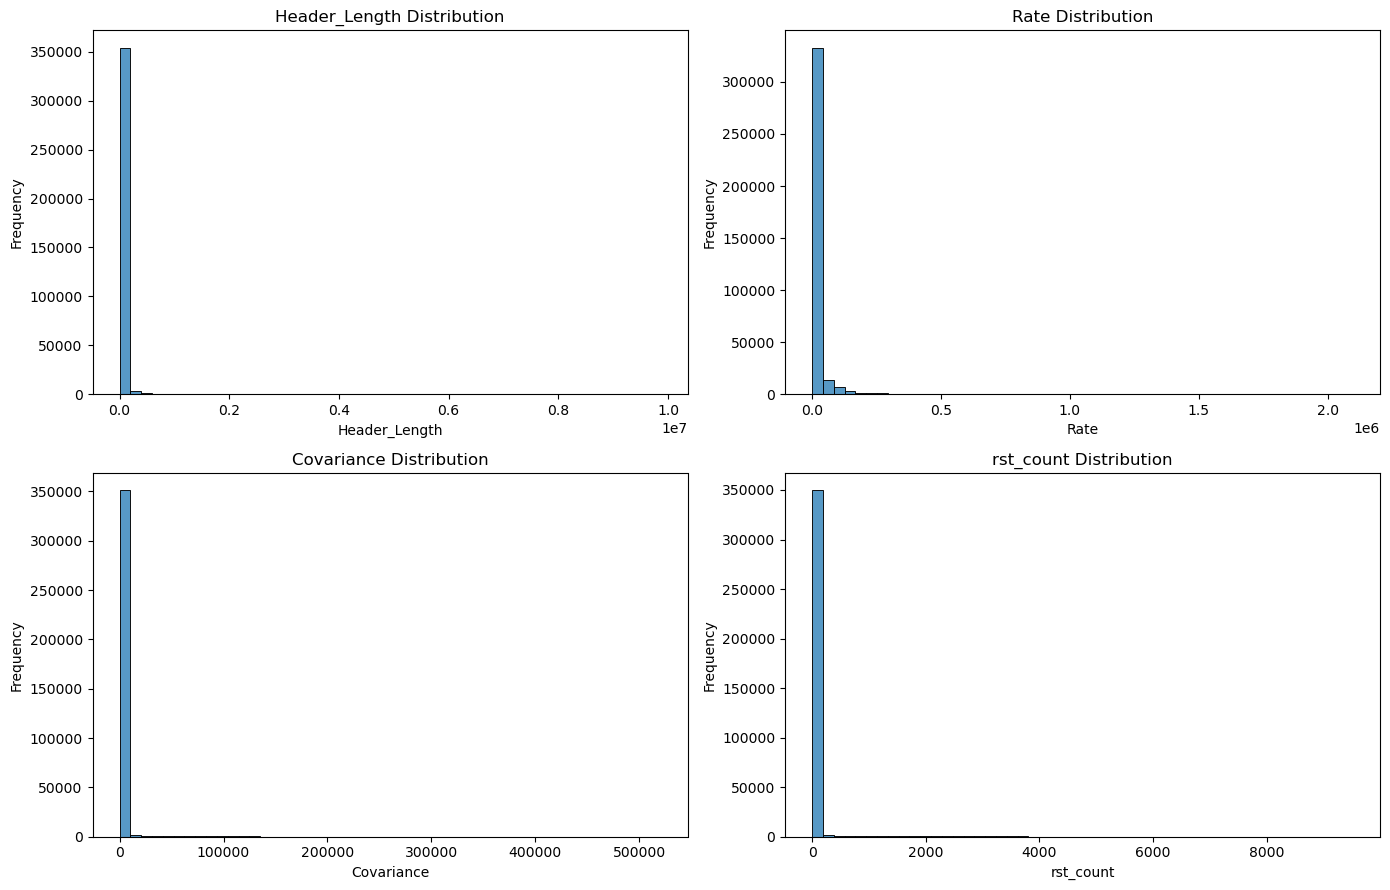

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

selected_features = ["Header_Length", "Rate", "Covariance", "rst_count"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, feature in enumerate(selected_features):
    sns.histplot(
        data=df_train_sample,
        x=feature,
        bins=50,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} Distribution")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 10.1. Log-Transformed Feature Distributions

Logarithmic transformation is applied for visualization purposes to improve the interpretability of highly right-skewed feature distributions without modifying the original dataset.

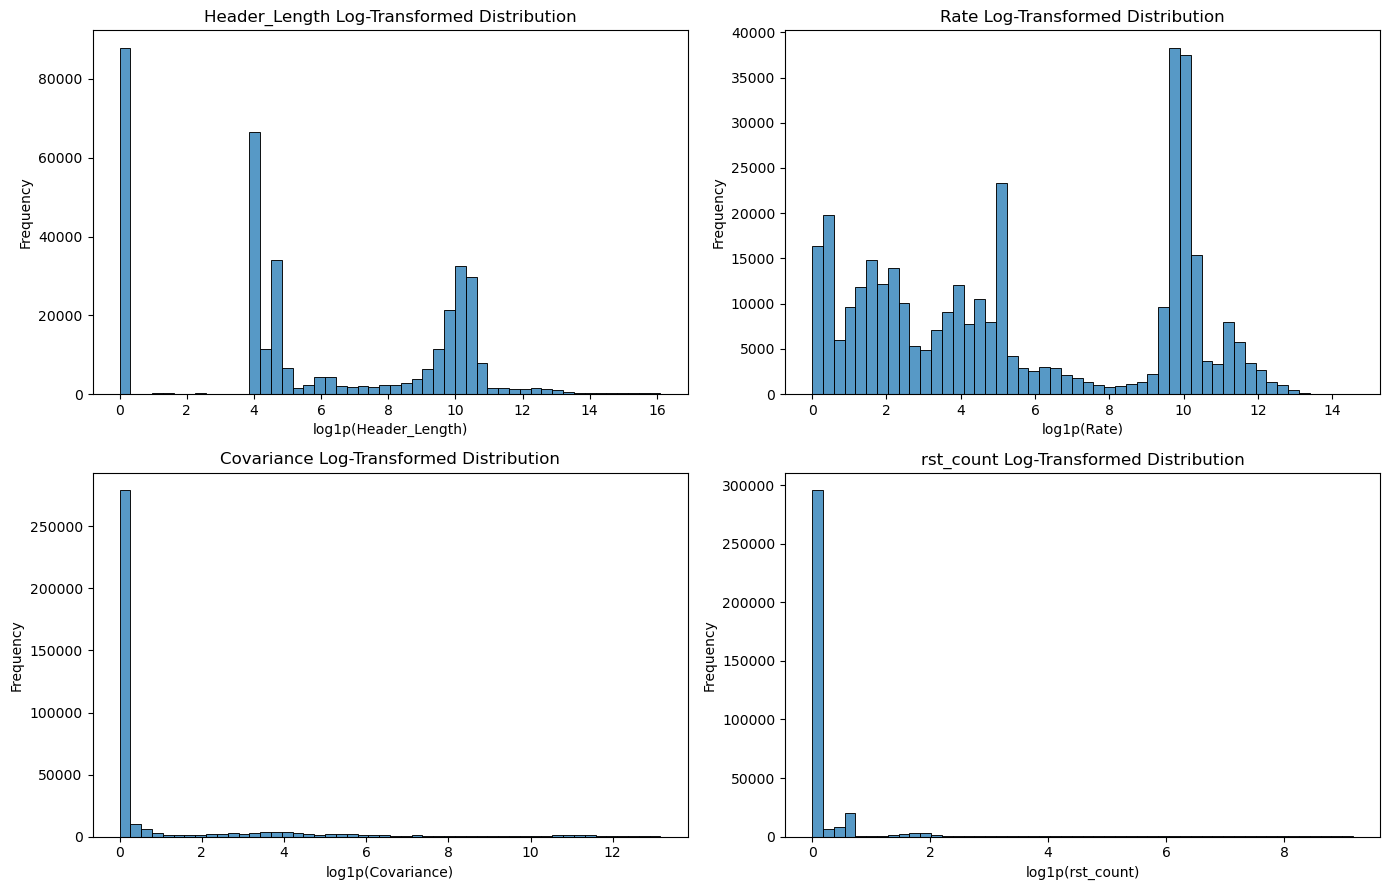

In [25]:
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, feature in enumerate(selected_features):
    sns.histplot(
        x=np.log1p(df_train_sample[feature]),
        bins=50,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} Log-Transformed Distribution")
    axes[i].set_xlabel(f"log1p({feature})")
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 10.2. Findings

The original distributions exhibited strong right-skewness, with most observations concentrated at low values and relatively few observations extending toward large values.

Log-transformed visualizations revealed multiple concentration regions in `Header_Length` and `Rate`, while `Covariance` and `rst_count` remained predominantly zero-valued.

These findings highlight heterogeneous feature distributions and suggest that further class-specific analysis is necessary to understand their relationship with attack types.

## 10.3. Feature Distribution by Traffic Class

This analysis compares feature distributions between benign and attack traffic to investigate potential differences in network behavior and feature discriminative patterns.

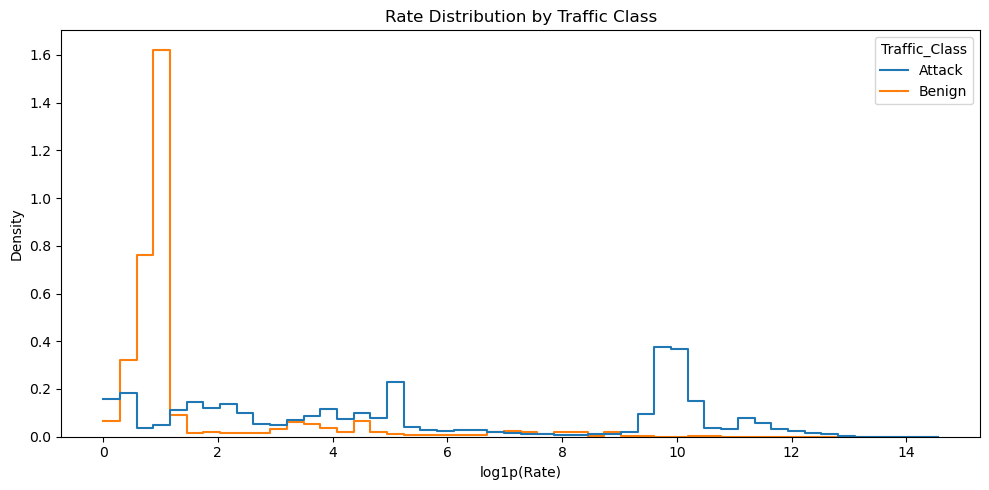

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = df_train_sample.copy()

df_plot["Log_Rate"] = np.log1p(df_plot["Rate"])
df_plot["Traffic_Class"] = df_plot["Label"].map({
    0: "Benign",
    1: "Attack"
})

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_plot,
    x="Log_Rate",
    hue="Traffic_Class",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Rate Distribution by Traffic Class")
plt.xlabel("log1p(Rate)")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

### 10.3.1. Findings

The `Rate` feature exhibited distinct distribution patterns between benign and attack traffic. Benign observations were predominantly concentrated at low values, whereas attack traffic showed a broader distribution with a pronounced concentration at higher values.

Although the distributions overlap in certain regions, these findings suggest that `Rate` may provide useful discriminative information for binary attack detection.

## 10.4. Additional Feature Distributions by Traffic Class

This analysis compares the distributions of `Header_Length`, `Covariance`, and `rst_count` between benign and attack traffic to investigate their potential discriminative characteristics.

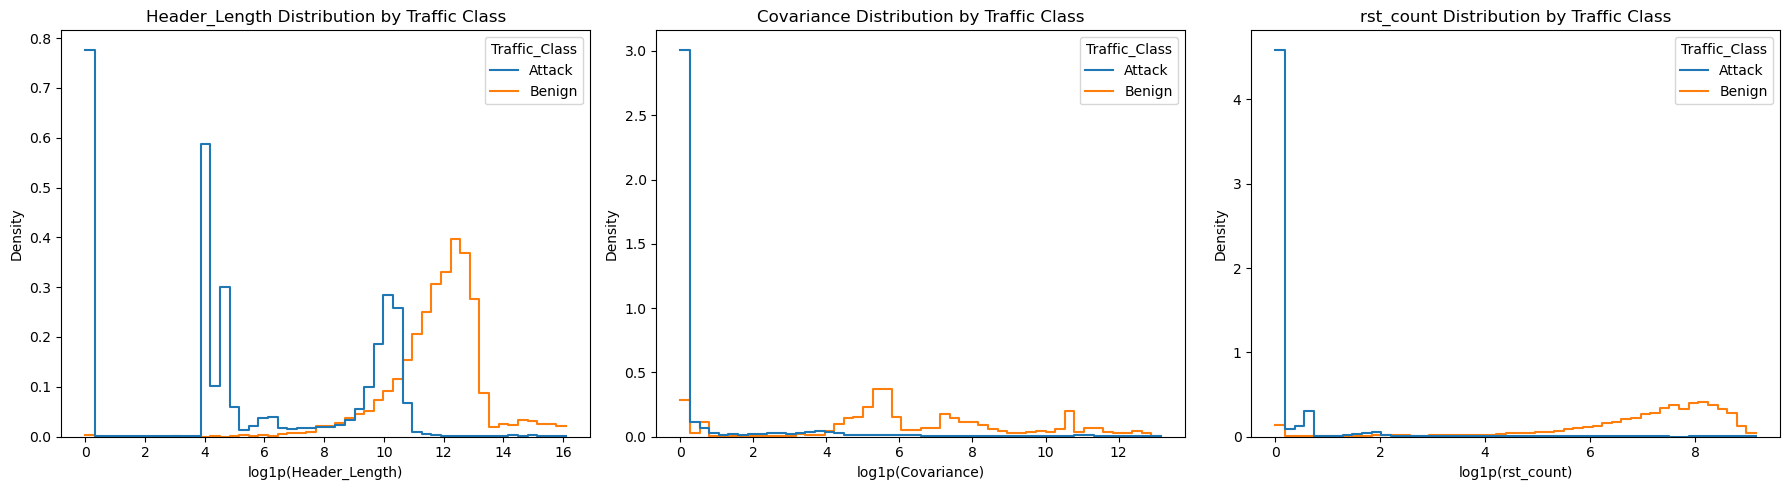

In [27]:
selected_features = ["Header_Length", "Covariance", "rst_count"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(selected_features):
    sns.histplot(
        data=df_plot,
        x=np.log1p(df_plot[feature]),
        hue="Traffic_Class",
        bins=50,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} Distribution by Traffic Class")
    axes[i].set_xlabel(f"log1p({feature})")
    axes[i].set_ylabel("Density")

plt.tight_layout()
plt.show()

### 10.4.1. Findings

The distributions of `Header_Length`, `Covariance`, and `rst_count` exhibited distinct patterns between benign and attack traffic.

Attack observations were predominantly concentrated at low or zero values for `Covariance` and `rst_count`, whereas benign traffic showed greater concentrations at higher values. The `Header_Length` feature also demonstrated different concentration regions across the two classes.

These findings suggest that the examined features may provide useful discriminative information for binary attack detection.

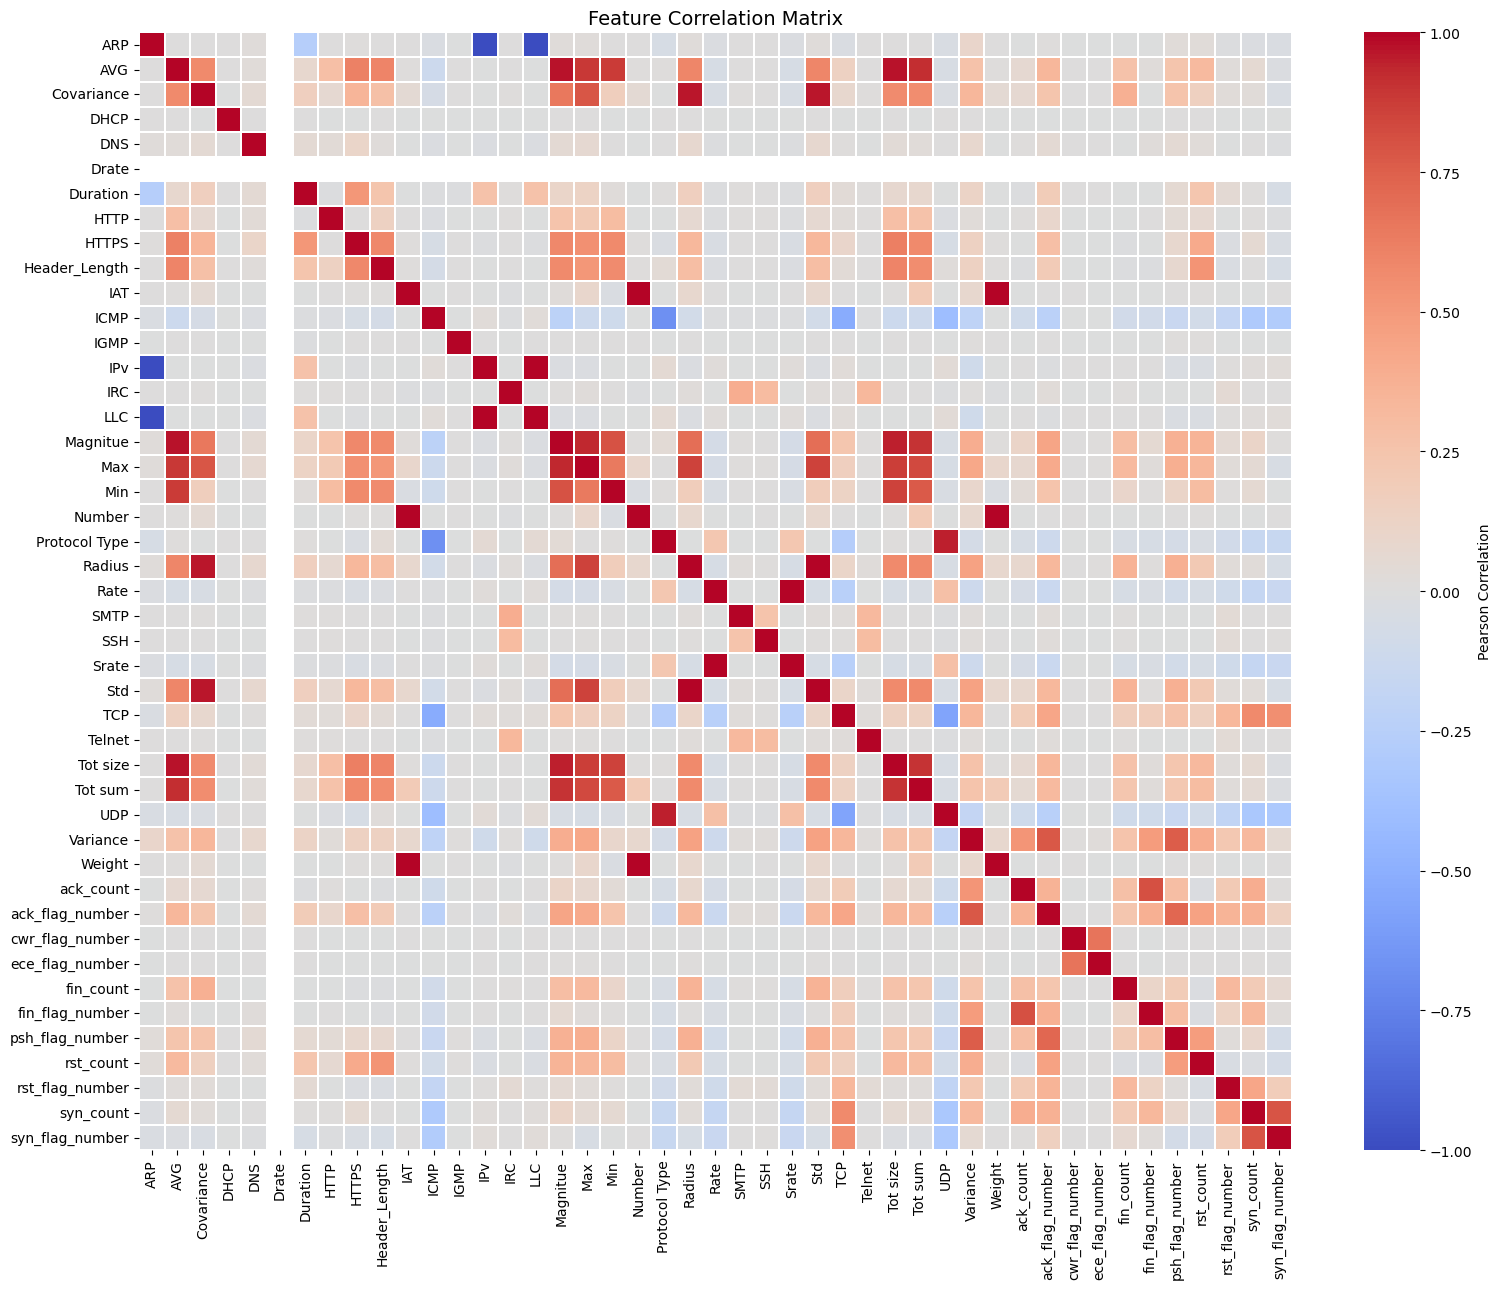

In [28]:
correlation_matrix = df_train_sample[feature_columns].corr(method="pearson")

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.2,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Feature Correlation Matrix", fontsize=14)
plt.tight_layout()
plt.show()

## 11.2. Highly Correlated Feature Pairs

Feature pairs with an absolute Pearson correlation coefficient of at least 0.90 are identified to examine potential feature redundancy.

In [30]:
def correlation_for_dropping(df, threshold=0.90):
    correlated_pairs = []
    corr = df.corr(method="pearson")

    for i in range(len(corr.columns)):
        for j in range(i):
            correlation = corr.iloc[i, j]

            if abs(correlation) > threshold:
                correlated_pairs.append({
                    "Feature_1": corr.columns[i],
                    "Feature_2": corr.columns[j],
                    "Correlation": correlation
                })

    return pd.DataFrame(correlated_pairs)


high_corr_pairs = correlation_for_dropping(
    df_train_sample[feature_columns],
    threshold=0.90
)

display(
    high_corr_pairs.sort_values(
        by="Correlation",
        key=lambda x: x.abs(),
        ascending=False
    ).reset_index(drop=True)
)

,Feature_1,Feature_2,Correlation
0,Srate,Rate,1.000000
1,LLC,IPv,1.000000
2,IPv,ARP,-1.000000
3,LLC,ARP,-1.000000
4,Std,Radius,0.999971
5,Weight,Number,0.999815
6,Weight,IAT,0.998314
7,Number,IAT,0.997652
8,Magnitue,AVG,0.976240
9,Tot size,AVG,0.973796


## 11.3. Findings

Pearson correlation analysis identified 17 feature pairs with absolute correlation coefficients greater than 0.90.

Exact feature duplication was previously confirmed for `Rate–Srate` and `IPv–LLC`. Several additional feature pairs exhibited strong linear relationships, indicating potential redundancy.

However, high correlation alone does not justify feature removal. The identified relationships will be considered during feature selection and evaluated based on their contribution to model performance.

No features were removed at this stage.

# 12. Outlier Analysis

This section examines potential outliers using boxplots. Extreme observations are evaluated as possible characteristics of network traffic rather than automatically treated as erroneous records.

## 12.1. Boxplot-Based Outlier Visualization

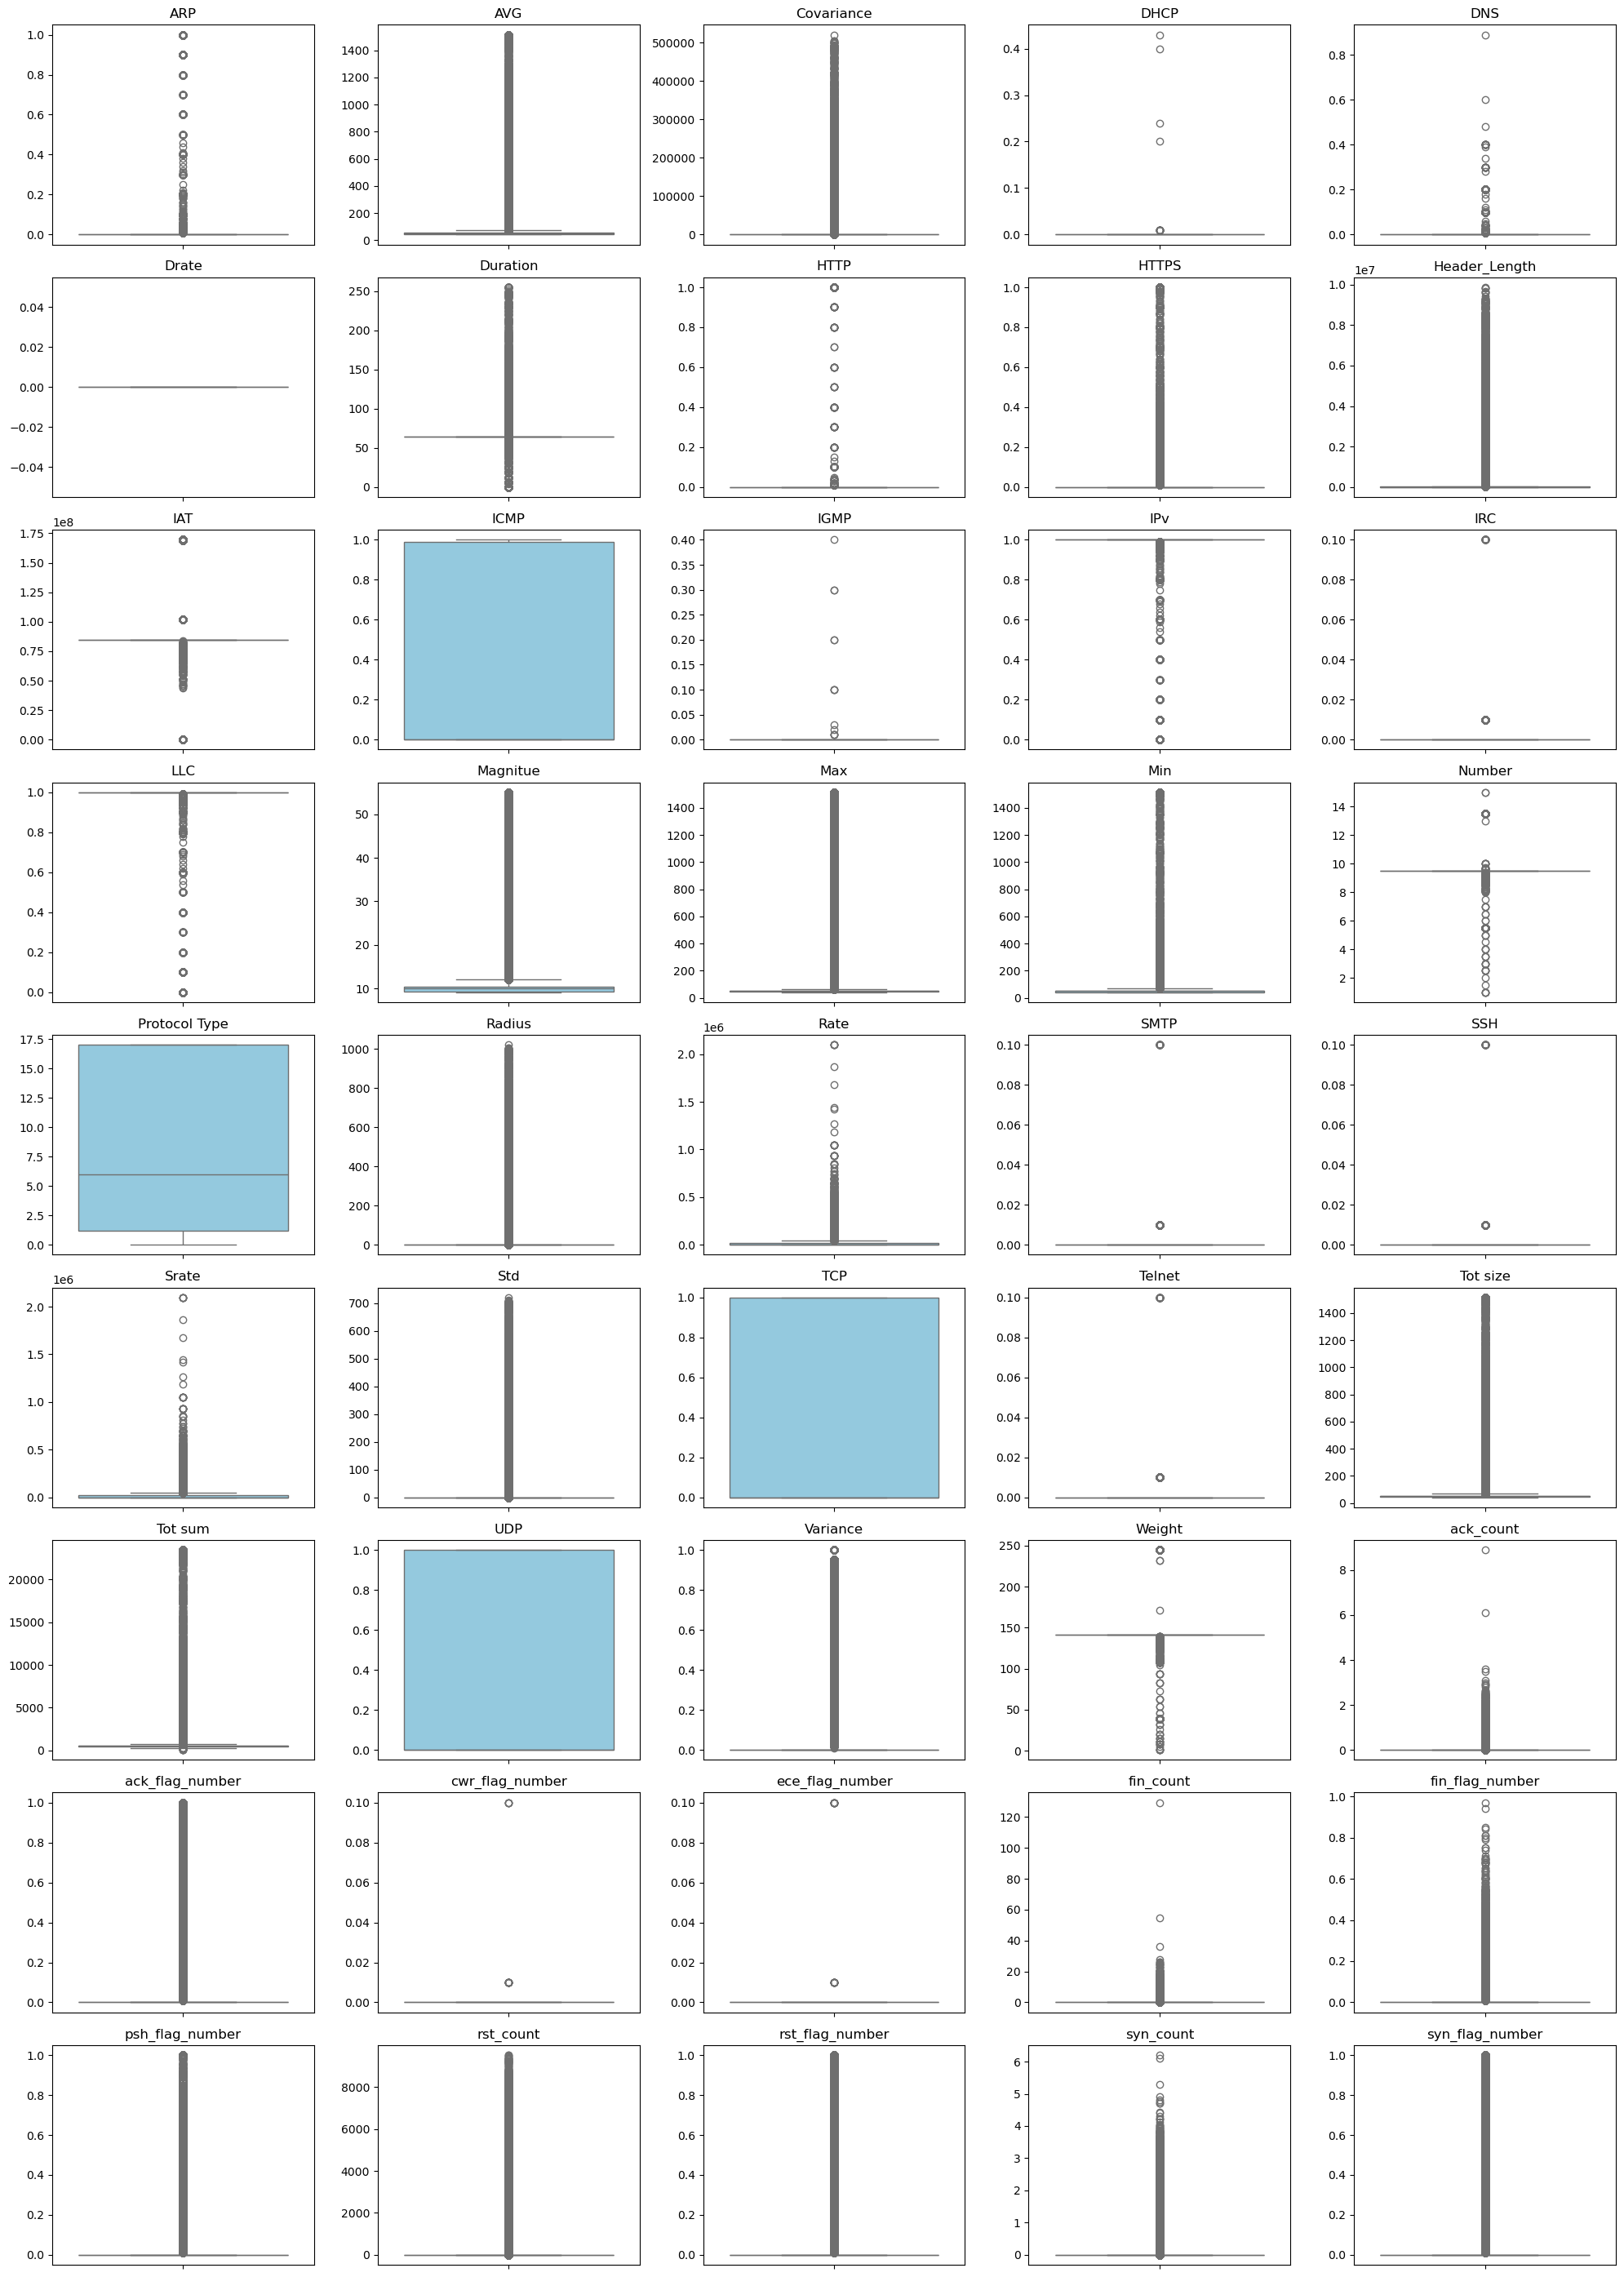

In [31]:
fig, axes = plt.subplots(9, 5, figsize=(20, 28))
axes = axes.flatten()

for i, feature in enumerate(feature_columns):
    sns.boxplot(
        y=df_train_sample[feature],
        ax=axes[i],
        color="skyblue"
    )

    axes[i].set_title(feature)
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

## 12.2. Class-Wise Outlier Visualization

Selected numerical traffic features are examined across benign and attack classes to investigate differences in their distributions and extreme observations.

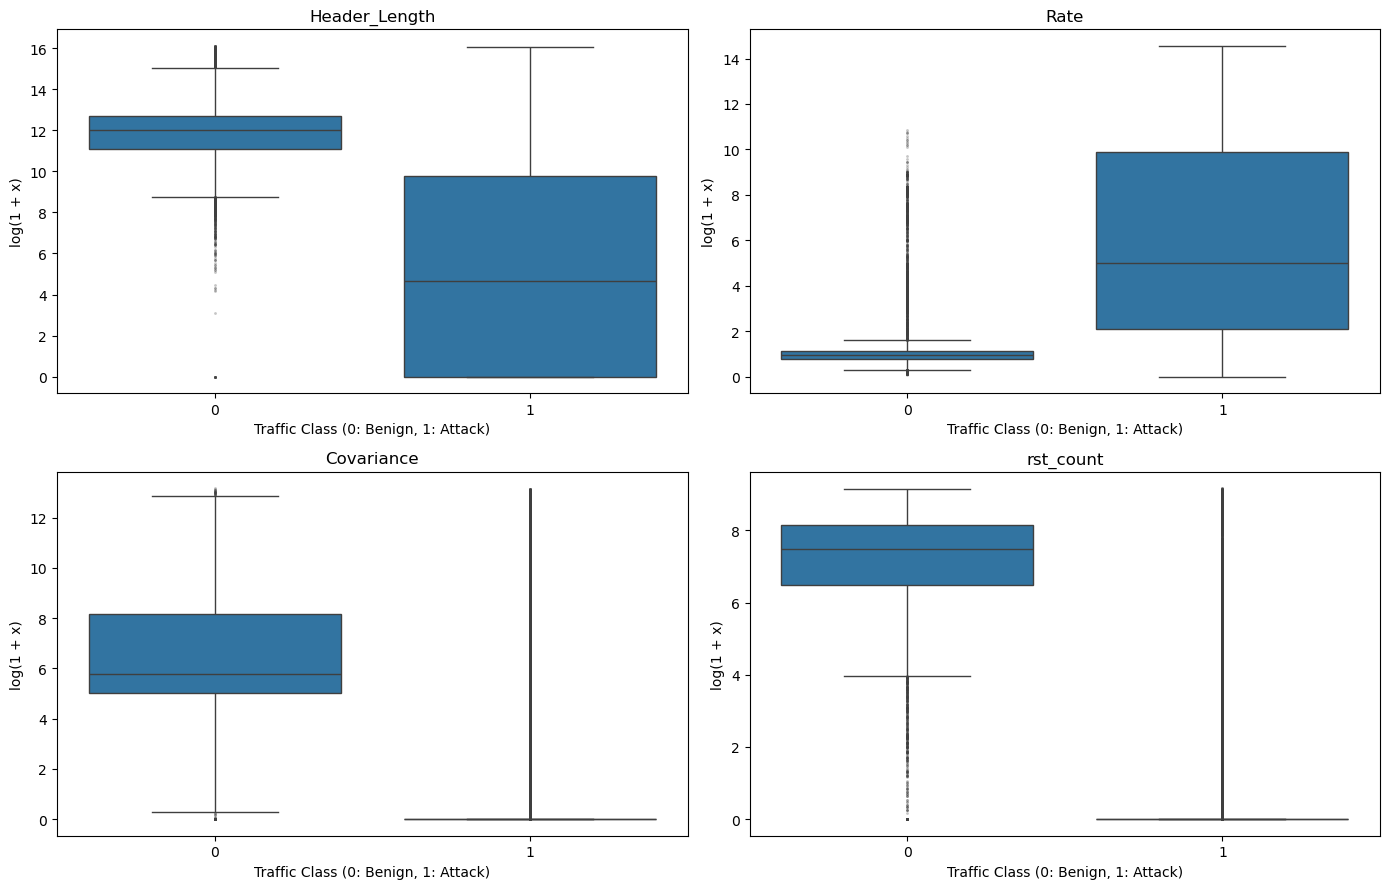

In [33]:
selected_features = ["Header_Length", "Rate", "Covariance", "rst_count"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, feature in enumerate(selected_features):
    sns.boxplot(
        data=df_train_sample,
        x="Label",
        y=np.log1p(df_train_sample[feature]),
        ax=axes[i],
        showfliers=True,
        flierprops={"marker": ".", "markersize": 2, "alpha": 0.3}

    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Traffic Class (0: Benign, 1: Attack)")
    axes[i].set_ylabel("log(1 + x)")

plt.tight_layout()
plt.show()

## 12.3. IQR-Based Outlier Detection

The Interquartile Range (IQR) method is applied to all 45 numerical features to quantify potential outliers in the training sample.

Observations outside the interval [Q1 − 1.5 × IQR, Q3 + 1.5 × IQR] are flagged as potential outliers. No observations are removed during this analysis.

In [34]:
def detect_outliers_iqr(df):
    results = []

    for column in df.columns:
        q1 = df[column].quantile(0.25)
        q3 = df[column].quantile(0.75)

        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outlier_count = (
            (df[column] < lower_bound) |
            (df[column] > upper_bound)
        ).sum()

        results.append({
            "Feature": column,
            "IQR": iqr,
            "Outlier_Count": outlier_count,
            "Outlier_Percentage": outlier_count / len(df) * 100
        })

    return pd.DataFrame(results)


outlier_summary = detect_outliers_iqr(
    df_train_sample[feature_columns]
)

display(
    outlier_summary.sort_values(
        by="Outlier_Percentage",
        ascending=False
    ).reset_index(drop=True)
)

,Feature,IQR,Outlier_Count,Outlier_Percentage
0,Std,0.000000,89366,24.748886
1,Covariance,0.000000,87747,24.300523
2,Variance,0.000000,87747,24.300523
3,Radius,0.000000,87747,24.300523
4,syn_count,0.000000,79958,22.143449
5,syn_flag_number,0.000000,76564,21.203519
6,rst_count,0.000000,73772,20.430307
7,ack_flag_number,0.000000,66036,18.287911
8,fin_count,0.000000,48619,13.464473
9,rst_flag_number,0.000000,42995,11.906971


### 12.3. Findings

The IQR-based analysis revealed varying proportions of potential outliers across the 45 numerical features.

The highest proportions were observed in `Std` (24.75%), `Covariance` (24.30%), `Variance` (24.30%), and `Radius` (24.30%). These features exhibited zero interquartile ranges, limiting the interpretability of conventional IQR-based outlier detection.

Features such as `Rate` (7.17%) and `Header_Length` (3.53%) also contained observations outside their respective IQR boundaries.

Given the zero-inflated distributions and the possibility that extreme observations represent meaningful attack characteristics, no outliers were removed during exploratory analysis.

# 13. Feature Selection and Preprocessing Decisions

This section identifies redundant and non-informative features based on the exploratory analysis. Feature removal decisions are derived from the training data and applied consistently to the training and test datasets.


## 13.1. Removal of Constant and Duplicate Features

The `Drate` feature was identified as constant, while `Srate` and `LLC` were confirmed to be exact duplicates of `Rate` and `IPv`, respectively.

In [35]:
features_to_drop = ["Drate", "Srate", "LLC"]

selected_features = [
    column for column in feature_columns
    if column not in features_to_drop
]

print("Original feature count:", len(feature_columns))
print("Removed feature count:", len(features_to_drop))
print("Remaining feature count:", len(selected_features))
print("Removed features:", features_to_drop)

Original feature count: 45
Removed feature count: 3
Remaining feature count: 42
Removed features: ['Drate', 'Srate', 'LLC']


### 13.1. Findings

Three features were selected for removal based on the exploratory analysis:

- `Drate`: Constant feature with zero variance.
- `Srate`: Exact duplicate of `Rate`.
- `LLC`: Exact duplicate of `IPv`.

The number of features was reduced from 45 to 42 in the selected feature list.

No modifications were made to the original training or test datasets at this stage.

## 13.2. Feature Selection Verification

The selected feature set is verified against the training and test datasets to ensure consistent feature availability before preprocessing and model development.

In [36]:
missing_train_features = set(selected_features) - set(df_train_full.columns)
missing_test_features = set(selected_features) - set(df_test_full.columns)

print("Missing features in training dataset:", missing_train_features)
print("Missing features in test dataset:", missing_test_features)

print("Selected feature count:", len(selected_features))

Missing features in training dataset: set()
Missing features in test dataset: set()
Selected feature count: 42


### 13.2. Findings

All 42 selected features were successfully verified in both the training and test datasets.

No missing features were identified, and consistent feature ordering was confirmed across both datasets.

The selected feature set is therefore ready for subsequent preprocessing and model development.

## 13.3. Feature Scaling Strategy

The numerical features exhibit substantially different value ranges and highly skewed distributions.

Feature scaling will be applied according to the requirements of each machine learning algorithm. StandardScaler will be considered for scale-sensitive models, while tree-based models will be evaluated without mandatory scaling.

To prevent data leakage, scaling parameters will be estimated exclusively from the training folds using a machine learning pipeline.

In [37]:
scaling_summary = df_train_sample[selected_features].agg(
    ["min", "max", "mean", "std"]
).T

scaling_summary["Range"] = (
    scaling_summary["max"] - scaling_summary["min"]
)

display(
    scaling_summary.sort_values(
        by="Range",
        ascending=False
    ).style.format("{:,.4f}")
)

,min,max,mean,std,Range
IAT,0.0000,"169,469,425.4462","84,701,701.8547","19,251,793.8377","169,469,425.4462"
Header_Length,0.0000,"9,861,738.8000","35,906.2623","329,903.2464","9,861,738.8000"
Rate,0.0000,"2,097,152.0000","15,104.5703","38,948.2187","2,097,152.0000"
Covariance,0.0000,"520,437.8875","2,928.7014","23,207.6122","520,437.8875"
Tot sum,50.0000,"23,467.0000",657.9199,"1,108.6336","23,417.0000"
rst_count,0.0000,"9,518.5000",73.9616,539.1911,"9,518.5000"
Tot size,42.0000,"1,514.0000",62.5892,97.0261,"1,472.0000"
AVG,42.0000,"1,514.0000",62.5783,97.1103,"1,472.0000"
Min,42.0000,"1,514.0000",55.9886,74.9807,"1,472.0000"
Max,42.0000,"1,514.0000",76.1622,146.9724,"1,472.0000"


### 13.3. Findings

The feature scaling analysis revealed substantial differences in numerical ranges and standard deviations across the 42 selected features.

`IAT`, `Header_Length`, `Rate`, and `Covariance` exhibited particularly large value ranges, whereas several protocol-related features were bounded within narrow intervals.

These findings indicate that feature scaling may be necessary for scale-sensitive machine learning algorithms. However, scaling requirements depend on the selected model architecture.

No scaling transformations were applied during this stage. Appropriate scaling methods will be incorporated into model training pipelines to prevent data leakage during cross-validation.

## 13.4. Class Imbalance Analysis and Handling Strategy

The binary class distribution is examined using the full training dataset to quantify class imbalance.

Class frequencies, percentages, and the imbalance ratio are calculated to assess potential bias toward the majority class.

Appropriate imbalance handling strategies will be considered during model development without modifying the independent test dataset.

In [38]:
class_counts = (
    df_train_full["Label"]
    .value_counts()
    .sort_index()
)

class_percentages = (
    df_train_full["Label"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

class_summary = pd.DataFrame({
    "Class": ["Benign", "Attack"],
    "Count": class_counts.values,
    "Percentage": class_percentages.values
})

imbalance_ratio = class_counts.max() / class_counts.min()

display(
    class_summary.style.format({
        "Count": "{:,.0f}",
        "Percentage": "{:.2f}%"
    })
)

print(f"Class imbalance ratio: {imbalance_ratio:.2f}:1")

,Class,Count,Percentage
0,Benign,"192,732",2.69%
1,Attack,"6,968,099",97.31%


Class imbalance ratio: 36.15:1


### 13.4. Findings

The full training dataset contains 192,732 benign records (2.69%) and 6,968,099 attack records (97.31%), resulting in a class imbalance ratio of approximately 36.15:1.

This substantial imbalance may bias classification models toward the majority attack class and produce misleadingly high accuracy scores.

Class weighting and appropriate evaluation metrics, including class-specific precision, recall, F1-score, and confusion matrices, will be considered during model development.

No resampling or class balancing was performed at this stage. The original class distribution was preserved.

# 14. Final Data Preparation

## 14.1. Feature and Target Separation

The 42 selected features are separated from the binary target variable to prepare the training and test datasets for machine learning.

`Attack_Type` and `Source_File` are excluded from the model inputs to prevent target-related information leakage.

The original training and test DataFrames remain unchanged.

In [39]:
X_train = df_train_full[selected_features]
y_train = df_train_full["Label"]

X_test = df_test_full[selected_features]
y_test = df_test_full["Label"]

print("Training features:", X_train.shape)
print("Training target:", y_train.shape)

print("Test features:", X_test.shape)
print("Test target:", y_test.shape)

print("Feature consistency:", X_train.columns.equals(X_test.columns))
print("Missing training values:", X_train.isna().sum().sum())
print("Missing test values:", X_test.isna().sum().sum())

Training features: (7160831, 42)
Training target: (7160831,)
Test features: (1614182, 42)
Test target: (1614182,)
Feature consistency: True
Missing training values: 0
Missing test values: 0


### 14.1. Findings

The final training dataset contains 7,160,831 records and 42 selected features, while the test dataset contains 1,614,182 records and the same 42 features.

The binary target variable was successfully separated from the input features in both datasets.

Feature consistency was confirmed, with identical feature names and ordering across the training and test datasets.

No missing values were detected in either feature matrix. The original datasets remain unchanged, and no outlier removal or scaling transformations were performed.


## 14.2. Training–Test Overlap Verification

Potential data leakage between the training and test datasets is reassessed using the final set of 42 selected features.

Feature-level record hashes are compared to identify test observations that also appear in the training dataset.

No records are removed at this stage. The results will inform the final evaluation strategy.


In [40]:
train_hashes = pd.util.hash_pandas_object(
    X_train, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test, index=False
)

overlap_mask = test_hashes.isin(train_hashes)

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Overlapping test records:", overlap_mask.sum())
print("Overlapping test percentage:", f"{overlap_mask.mean() * 100:.4f}%")
print("Non-overlapping test records:", (~overlap_mask).sum())

Training records: 7160831
Test records: 1614182
Overlapping test records: 357
Overlapping test percentage: 0.0221%
Non-overlapping test records: 1613825


### 14.2. Findings

The overlap verification identified 357 test records (0.0221%) with feature values matching records in the training dataset.

A total of 1,613,825 test records did not match any training records based on the 42 selected features.

The overlap count remained unchanged after feature selection, indicating that removing the three redundant features did not introduce additional matches.

Although the overlap proportion is small, these records represent a potential source of data leakage during independent model evaluation.

The overlapping test records will be excluded from the final evaluation set, while the original test dataset will be preserved for reproducibility.


## 14.3. Independent Test Set Preparation

An independent evaluation set is prepared by excluding test observations whose selected feature values match records in the training dataset.

The original training and test datasets are preserved. Only the overlapping test observations are excluded from the final evaluation set.

Feature–target alignment and dataset dimensions are verified after filtering.


In [41]:
X_test_clean = X_test.loc[~overlap_mask]
y_test_clean = y_test.loc[~overlap_mask]

print("Original test features:", X_test.shape)
print("Clean test features:", X_test_clean.shape)
print("Clean test target:", y_test_clean.shape)

print("Removed overlapping records:", len(X_test) - len(X_test_clean))

print("Feature consistency:", X_train.columns.equals(X_test_clean.columns))
print("Index alignment:", X_test_clean.index.equals(y_test_clean.index))

Original test features: (1614182, 42)
Clean test features: (1613825, 42)
Clean test target: (1613825,)
Removed overlapping records: 357
Feature consistency: True
Index alignment: True


### 14.3. Findings

The independent evaluation set was successfully prepared by excluding 357 test records that overlapped with the training dataset.

The resulting test set contains 1,613,825 observations and 42 selected features.

Feature consistency and feature–target index alignment were successfully verified.

The original training and test datasets remain unchanged. The filtered test set will be used for independent model evaluation.


## 14.4. Final Dataset Validation

The prepared training and independent test datasets are validated before model development.

The validation examines feature consistency, target labels, feature–target alignment, and potential overlap between training and test observations.

No additional preprocessing transformations are applied at this stage.


In [42]:
print("Training dataset:", X_train.shape)
print("Independent test dataset:", X_test_clean.shape)

print("Training labels:", sorted(y_train.unique()))
print("Test labels:", sorted(y_test_clean.unique()))

print("Training alignment:", X_train.index.equals(y_train.index))
print("Test alignment:", X_test_clean.index.equals(y_test_clean.index))

print("Feature consistency:", X_train.columns.equals(X_test_clean.columns))

print("Missing training values:", X_train.isna().sum().sum())
print("Missing test values:", X_test_clean.isna().sum().sum())

print("Remaining overlap:", overlap_mask.loc[X_test_clean.index].sum())

Training dataset: (7160831, 42)
Independent test dataset: (1613825, 42)
Training labels: [np.int64(0), np.int64(1)]
Test labels: [np.int64(0), np.int64(1)]
Training alignment: True
Test alignment: True
Feature consistency: True
Missing training values: 0
Missing test values: 0
Remaining overlap: 0


### 14.4. Findings

The final training dataset contains 7,160,831 observations and 42 selected features, while the independent test dataset contains 1,613,825 observations and the same 42 features.

Both datasets contain the expected binary target labels (0: Benign, 1: Attack).

Feature consistency, feature–target index alignment, and missing value checks were successfully validated.

No overlapping observations remain in the independent test set based on the selected feature values.

The datasets are ready for subsequent machine learning experiments. Feature scaling and class imbalance handling will be addressed within the model development workflow.

# 15. Export of Modeling-Ready Datasets

## 15.1. Parquet Export

The finalized training and independent test datasets are exported in Parquet format for subsequent machine learning experiments.

Only the 42 selected features and the binary target variable are stored. The datasets are written in chunks to reduce memory consumption during the export process.

This approach avoids repeating the preprocessing workflow in subsequent notebooks.

In [43]:
import pyarrow as pa
import pyarrow.parquet as pq

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

train_output = output_dir / "train_modeling.parquet"
test_output = output_dir / "test_modeling.parquet"

def write_parquet_in_chunks(X, y, output_path, chunk_size=250_000):
    writer = None

    try:
        for start in range(0, len(X), chunk_size):
            end = min(start + chunk_size, len(X))

            chunk = pd.concat(
                [
                    X.iloc[start:end],
                    y.iloc[start:end].rename("Label")
                ],
                axis=1
            )

            table = pa.Table.from_pandas(
                chunk,
                preserve_index=False
            )

            if writer is None:
                writer = pq.ParquetWriter(
                    output_path,
                    table.schema,
                    compression="snappy"
                )

            writer.write_table(table)

            print(f"{end:,} / {len(X):,} records written")

            del chunk
            del table

    finally:
        if writer is not None:
            writer.close()


write_parquet_in_chunks(
    X_train,
    y_train,
    train_output
)

write_parquet_in_chunks(
    X_test_clean,
    y_test_clean,
    test_output
)

print("\nTraining dataset:", train_output)
print("Test dataset:", test_output)

250,000 / 7,160,831 records written
500,000 / 7,160,831 records written
750,000 / 7,160,831 records written
1,000,000 / 7,160,831 records written
1,250,000 / 7,160,831 records written
1,500,000 / 7,160,831 records written
1,750,000 / 7,160,831 records written
2,000,000 / 7,160,831 records written
2,250,000 / 7,160,831 records written
2,500,000 / 7,160,831 records written
2,750,000 / 7,160,831 records written
3,000,000 / 7,160,831 records written
3,250,000 / 7,160,831 records written
3,500,000 / 7,160,831 records written
3,750,000 / 7,160,831 records written
4,000,000 / 7,160,831 records written
4,250,000 / 7,160,831 records written
4,500,000 / 7,160,831 records written
4,750,000 / 7,160,831 records written
5,000,000 / 7,160,831 records written
5,250,000 / 7,160,831 records written
5,500,000 / 7,160,831 records written
5,750,000 / 7,160,831 records written
6,000,000 / 7,160,831 records written
6,250,000 / 7,160,831 records written
6,500,000 / 7,160,831 records written
6,750,000 / 7,160,

### Export Summary

The finalized modeling datasets were successfully exported in Parquet format.

The training and independent test datasets contain the 42 selected features and the binary target variable, enabling subsequent modeling notebooks to reuse the prepared data without repeating the preprocessing workflow.

## 15.2. Export Verification

The exported Parquet files are verified using file metadata to confirm their dimensions without reloading the complete datasets into memory.

In [44]:
train_metadata = pq.ParquetFile(train_output)
test_metadata = pq.ParquetFile(test_output)

print("Training rows:", train_metadata.metadata.num_rows)
print("Training columns:", train_metadata.metadata.num_columns)

print("Test rows:", test_metadata.metadata.num_rows)
print("Test columns:", test_metadata.metadata.num_columns)

Training rows: 7160831
Training columns: 43
Test rows: 1613825
Test columns: 43


### 15.2. Findings

The exported Parquet files were successfully verified.

The training dataset contains 7,160,831 records and 43 columns, while the independent test dataset contains 1,613,825 records and 43 columns.

Each exported dataset includes the 42 selected features and the binary target variable (`Label`).